# Is the Race Decided on Saturday? An EDA of Formula 1 (1950–2024)

**Majed Alotaibi**, AI undergraduate, University of Hail. Unit 3 Final Project.

## Step 1: Dataset

**Formula 1 World Championship (1950–2020)** by Rohan Rao on Kaggle:
https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020

The data comes from the Ergast API. It has 14 CSV files that cover every race since 1950:
results, drivers, teams, circuits, lap times, pit stops and more. The name says 2020, but the
files are updated, and the version I downloaded runs to the end of the 2024 season.

I use 5 of the 14 files: `results`, `races`, `drivers`, `constructors` and `status`, plus
`circuits` for circuit names in the dashboard.

**Why I picked it:** I am an F1 fan, so I already had questions I wanted to answer. It is also a
real relational dataset. The tables have to be joined by ID, and there is real cleaning work to do
(missing values stored as text, times stored as strings, inconsistent status labels).

## Step 2: Problem definition

**Main question: Is the race decided on Saturday?** In other words, how much does qualifying
(the grid position) decide the result on Sunday?

Supporting questions:
1. How strongly does grid position predict finishing position, and has that link grown stronger since 2010?
2. Does one constructor dominate each era?
3. Have cars become more reliable (fewer DNFs, fewer mechanical failures)?

**Scope.** For grid vs result I use **2010–2024**, because the cars and rules in that period are
more comparable (no refuelling, same points system). For reliability and dominance I use the full
**1950–2024** range. Every season in the data is complete, so I stop at 2024.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 40)

RAW = Path("../data/raw")
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

# One style for every plot: dark background, red accent, grey for the rest
RED = "#FF2B17"
GREY = "#5C5C66"
LIGHT = "#C8C8D0"
BG = "#15151E"

plt.style.use("dark_background")
plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": BG,
    "savefig.facecolor": BG,
    "axes.edgecolor": "#3A3A44",
    "axes.grid": True,
    "grid.color": "#2E2E38",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 110,
    "font.family": "DejaVu Sans",
})


def save(fig, name):
    """Save a figure into reports/figures so the PDF report can use it."""
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## Step 3: Loading and structure

First I load the files with plain `read_csv`, no options, to see what the raw data really looks like.

In [2]:
results_raw = pd.read_csv(RAW / "results.csv")
races_raw = pd.read_csv(RAW / "races.csv")
drivers_raw = pd.read_csv(RAW / "drivers.csv")
constructors_raw = pd.read_csv(RAW / "constructors.csv")
status_raw = pd.read_csv(RAW / "status.csv")
circuits_raw = pd.read_csv(RAW / "circuits.csv")

for name, t in [("results", results_raw), ("races", races_raw), ("drivers", drivers_raw),
                ("constructors", constructors_raw), ("status", status_raw), ("circuits", circuits_raw)]:
    print(f"{name:<13} {t.shape}")

results       (26759, 18)
races         (1125, 18)
drivers       (861, 9)
constructors  (212, 5)
status        (139, 2)
circuits      (77, 9)


### results.csv (raw)

In [3]:
results_raw.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


In [4]:
results_raw.shape

(26759, 18)

In [5]:
results_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26759 non-null  object 
 5   grid             26759 non-null  int64  
 6   position         26759 non-null  object 
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             26759 non-null  object 
 12  milliseconds     26759 non-null  object 
 13  fastestLap       26759 non-null  object 
 14  rank             26759 non-null  object 
 15  fastestLapTime   26759 non-null  object 
 16  fastestLapSpeed  26759 non-null  object 
 17  statusId    

In [6]:
results_raw.describe()

,resultId,raceId,driverId,constructorId,grid,positionOrder,points,laps,statusId
count,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000
mean,13380.977391,551.687283,278.673530,50.180537,11.134796,12.794051,1.987632,46.301768,17.224971
std,7726.134642,313.265036,282.703039,61.551498,7.202860,7.665951,4.351209,29.496557,26.026104
min,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000
25%,6690.500000,300.000000,57.000000,6.000000,5.000000,6.000000,0.000000,23.000000,1.000000
50%,13380.000000,531.000000,172.000000,25.000000,11.000000,12.000000,0.000000,53.000000,10.000000
75%,20069.500000,811.000000,399.500000,63.000000,17.000000,18.000000,2.000000,66.000000,14.000000
max,26764.000000,1144.000000,862.000000,215.000000,34.000000,39.000000,50.000000,200.000000,141.000000


In [7]:
results_raw.isnull().sum()

resultId           0
raceId             0
driverId           0
constructorId      0
number             0
grid               0
position           0
positionText       0
positionOrder      0
points             0
laps               0
time               0
milliseconds       0
fastestLap         0
rank               0
fastestLapTime     0
fastestLapSpeed    0
statusId           0
dtype: int64

`isnull()` says nothing is missing, and columns like `position` and `milliseconds` are `object`
(text) instead of numbers. That is a warning sign. Looking at the values shows why:

In [8]:
MISSING = "\\N"
for col in ["position", "milliseconds", "fastestLapTime", "fastestLapSpeed"]:
    n = (results_raw[col] == MISSING).sum()
    print(f"{col:<16} {MISSING} count: {n:>6}   example value: {results_raw[col].iloc[0]}")

position         \N count:  10953   example value: 1
milliseconds     \N count:  19079   example value: 5690616
fastestLapTime   \N count:  18507   example value: 1:27.452
fastestLapSpeed  \N count:  18507   example value: 218.300


Missing values are stored as the text `\N`, so pandas does not see them as missing.

### Merged table (raw)

Next I join the tables into one row per driver per race. Several tables have a `name` column,
so I rename them during the merge.

In [9]:
def merge_tables(results, races, drivers, constructors, status, circuits):
    """Join the six tables into one row per driver per race."""
    races = races[["raceId", "year", "round", "circuitId", "name", "date"]].rename(columns={"name": "race_name"})
    drivers = drivers[["driverId", "forename", "surname", "nationality"]].rename(columns={"nationality": "driver_nationality"})
    constructors = constructors[["constructorId", "name", "nationality"]].rename(
        columns={"name": "team", "nationality": "team_nationality"})
    circuits = circuits[["circuitId", "name", "country"]].rename(columns={"name": "circuit_name"})

    return (results
            .merge(races, on="raceId", how="left")
            .merge(drivers, on="driverId", how="left")
            .merge(constructors, on="constructorId", how="left")
            .merge(status, on="statusId", how="left")
            .merge(circuits, on="circuitId", how="left"))


merged_raw = merge_tables(results_raw, races_raw, drivers_raw, constructors_raw, status_raw, circuits_raw)
print(merged_raw.shape)
merged_raw.head()

(26759, 31)


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,year,round,circuitId,race_name,date,forename,surname,driver_nationality,team,team_nationality,status,circuit_name,country
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1,2008,1,1,Australian Grand Prix,2008-03-16,Lewis,Hamilton,British,McLaren,British,Finished,Albert Park Grand Prix Circuit,Australia
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1,2008,1,1,Australian Grand Prix,2008-03-16,Nick,Heidfeld,German,BMW Sauber,German,Finished,Albert Park Grand Prix Circuit,Australia
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1,2008,1,1,Australian Grand Prix,2008-03-16,Nico,Rosberg,German,Williams,British,Finished,Albert Park Grand Prix Circuit,Australia
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1,2008,1,1,Australian Grand Prix,2008-03-16,Fernando,Alonso,Spanish,Renault,French,Finished,Albert Park Grand Prix Circuit,Australia
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1,2008,1,1,Australian Grand Prix,2008-03-16,Heikki,Kovalainen,Finnish,McLaren,British,Finished,Albert Park Grand Prix Circuit,Australia


In [10]:
merged_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   resultId            26759 non-null  int64  
 1   raceId              26759 non-null  int64  
 2   driverId            26759 non-null  int64  
 3   constructorId       26759 non-null  int64  
 4   number              26759 non-null  object 
 5   grid                26759 non-null  int64  
 6   position            26759 non-null  object 
 7   positionText        26759 non-null  object 
 8   positionOrder       26759 non-null  int64  
 9   points              26759 non-null  float64
 10  laps                26759 non-null  int64  
 11  time                26759 non-null  object 
 12  milliseconds        26759 non-null  object 
 13  fastestLap          26759 non-null  object 
 14  rank                26759 non-null  object 
 15  fastestLapTime      26759 non-null  object 
 16  fast

In [11]:
merged_raw.describe()

,resultId,raceId,driverId,constructorId,grid,positionOrder,points,laps,statusId,year,round,circuitId
count,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000
mean,13380.977391,551.687283,278.673530,50.180537,11.134796,12.794051,1.987632,46.301768,17.224971,1991.394372,8.511192,23.820808
std,7726.134642,313.265036,282.703039,61.551498,7.202860,7.665951,4.351209,29.496557,26.026104,19.952885,5.070231,19.112002
min,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1950.000000,1.000000,1.000000
25%,6690.500000,300.000000,57.000000,6.000000,5.000000,6.000000,0.000000,23.000000,1.000000,1977.000000,4.000000,9.000000
50%,13380.000000,531.000000,172.000000,25.000000,11.000000,12.000000,0.000000,53.000000,10.000000,1991.000000,8.000000,18.000000
75%,20069.500000,811.000000,399.500000,63.000000,17.000000,18.000000,2.000000,66.000000,14.000000,2009.000000,12.000000,34.000000
max,26764.000000,1144.000000,862.000000,215.000000,34.000000,39.000000,50.000000,200.000000,141.000000,2024.000000,24.000000,80.000000


In [12]:
merged_raw.isnull().sum()

resultId              0
raceId                0
driverId              0
constructorId         0
number                0
grid                  0
position              0
positionText          0
positionOrder         0
points                0
laps                  0
time                  0
milliseconds          0
fastestLap            0
rank                  0
fastestLapTime        0
fastestLapSpeed       0
statusId              0
year                  0
round                 0
circuitId             0
race_name             0
date                  0
forename              0
surname               0
driver_nationality    0
team                  0
team_nationality      0
status                0
circuit_name          0
country               0
dtype: int64

The merge kept all 26,759 results rows (none lost, none duplicated), and every ID found a match,
so there are no real NaNs. But the `\N` problem is still hiding inside the text columns.

## Step 4: Data cleaning

### 4.1 Read `\N` as missing

Before and after using `na_values=['\\N']`:

In [13]:
results = pd.read_csv(RAW / "results.csv", na_values=["\\N"])
races = pd.read_csv(RAW / "races.csv", na_values=["\\N"])
drivers = pd.read_csv(RAW / "drivers.csv", na_values=["\\N"])
constructors = pd.read_csv(RAW / "constructors.csv", na_values=["\\N"])
status = pd.read_csv(RAW / "status.csv", na_values=["\\N"])
circuits = pd.read_csv(RAW / "circuits.csv", na_values=["\\N"])

cols = ["position", "time", "milliseconds", "fastestLap", "rank", "fastestLapTime", "fastestLapSpeed"]
pd.DataFrame({
    "missing before": results_raw[cols].isnull().sum(),
    "missing after": results[cols].isnull().sum(),
    "dtype before": results_raw[cols].dtypes,
    "dtype after": results[cols].dtypes,
})

,missing before,missing after,dtype before,dtype after
position,0,10953,object,float64
time,0,19079,object,object
milliseconds,0,19079,object,float64
fastestLap,0,18507,object,float64
rank,0,18249,object,float64
fastestLapTime,0,18507,object,object
fastestLapSpeed,0,18507,object,float64


### 4.2 Merge again and keep 1950–2024

I merge the clean tables. The Kaggle version I have ends with the 2024 season, but I still add
the year filter so a partial current season can never slip in if the data is re-downloaded.

In [14]:
df = merge_tables(results, races, drivers, constructors, status, circuits)
print("before year filter:", df.shape, " years", df["year"].min(), "-", df["year"].max())
df = df[df["year"].between(1950, 2024)].copy()
print("after year filter: ", df.shape)

before year filter: (26759, 31)  years 1950 - 2024
after year filter:  (26759, 31)


### 4.3 Convert text columns to numbers

In the raw load, `position`, `milliseconds` and `fastestLapSpeed` were text. With `na_values`
pandas can already parse them, but I still run `pd.to_numeric` to make the step explicit and to
turn any leftover text into NaN.

In [15]:
num_cols = ["position", "milliseconds", "fastestLapSpeed"]
print("raw dtypes:  ", dict(results_raw[num_cols].dtypes.astype(str)))
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
print("clean dtypes:", dict(df[num_cols].dtypes.astype(str)))

raw dtypes:   {'position': 'object', 'milliseconds': 'object', 'fastestLapSpeed': 'object'}
clean dtypes: {'position': 'float64', 'milliseconds': 'float64', 'fastestLapSpeed': 'float64'}


### 4.4 Fastest lap time to seconds

`fastestLapTime` looks like `"1:27.452"`. I turn it into seconds so it can be used as a number.

In [16]:
def lap_to_seconds(t):
    """'1:27.452' -> 87.452. Returns NaN for missing values."""
    if pd.isna(t):
        return np.nan
    minutes, seconds = str(t).split(":")
    return int(minutes) * 60 + float(seconds)


df["fastest_lap_sec"] = df["fastestLapTime"].apply(lap_to_seconds)
df[["fastestLapTime", "fastest_lap_sec"]].dropna().head()

,fastestLapTime,fastest_lap_sec
0,1:27.452,87.452
1,1:27.739,87.739
2,1:28.090,88.090
3,1:28.603,88.603
4,1:27.418,87.418


### 4.5 Grid 0

`grid == 0` means the driver started from the pit lane or had no grid slot. I keep these rows,
but I add `grid_clean` where 0 becomes NaN, and I use `grid_clean` for all grid analysis.

In [17]:
print("rows with grid == 0:", (df["grid"] == 0).sum())
df["grid_clean"] = df["grid"].replace(0, np.nan)
df[["grid", "grid_clean"]].describe()

rows with grid == 0: 1638


,grid,grid_clean
count,26759.000000,25121.000000
mean,11.134796,11.860834
std,7.202860,6.830260
min,0.000000,1.000000
25%,5.000000,6.000000
50%,11.000000,12.000000
75%,17.000000,17.000000
max,34.000000,34.000000


### 4.6 Names

The `name` columns were already renamed in the merge (`race_name`, `team`, `circuit_name`).
Now I build one `driver` column from first name and surname.

In [18]:
df["driver"] = df["forename"] + " " + df["surname"]
df[["race_name", "circuit_name", "team", "driver"]].head()

,race_name,circuit_name,team,driver
0,Australian Grand Prix,Albert Park Grand Prix Circuit,McLaren,Lewis Hamilton
1,Australian Grand Prix,Albert Park Grand Prix Circuit,BMW Sauber,Nick Heidfeld
2,Australian Grand Prix,Albert Park Grand Prix Circuit,Williams,Nico Rosberg
3,Australian Grand Prix,Albert Park Grand Prix Circuit,Renault,Fernando Alonso
4,Australian Grand Prix,Albert Park Grand Prix Circuit,McLaren,Heikki Kovalainen


### 4.7 Finished, starter and DNF

- `finished`: status is "Finished" or "+1 Lap", "+2 Laps" and so on. These drivers were classified.
- `starter`: False for entries that never really started the race
  (did not qualify, did not prequalify, withdrew, did not start, excluded, not classified).
- `dnf`: a starter who did not finish.

In [19]:
df["finished"] = df["status"].eq("Finished") | df["status"].str.match(r"^\+\d+ Lap")

non_starters = ["Did not qualify", "Did not prequalify", "Withdrew",
                "Did not start", "Excluded", "Not classified"]
df["starter"] = ~df["status"].isin(non_starters)
df["dnf"] = df["starter"] & ~df["finished"]

df[["finished", "starter", "dnf"]].sum()

finished    15161
starter     24975
dnf          9814
dtype: int64

There are more than 130 status labels. To study reliability I group the DNF reasons into three
types: crash/collision, other (disqualified, driver illness, generic "Retired" and so on), and
mechanical (everything else: engine, gearbox, brakes, hydraulics...).

In [20]:
crash_labels = {"Accident", "Collision", "Collision damage", "Spun off", "Fatal accident",
                "Puncture", "Tyre puncture", "Damage", "Debris"}
other_labels = {"Retired", "Disqualified", "Illness", "Injury", "Injured", "Physical", "Driver unwell",
                "Eye injury", "Safety concerns", "Safety", "Not restarted", "107% Rule", "Underweight",
                "Out of fuel", "Tyre", "Fuel rig", "Refuelling"}


def dnf_type(row):
    if not row["dnf"]:
        return np.nan
    if row["status"] in crash_labels:
        return "Crash/collision"
    if row["status"] in other_labels:
        return "Other"
    return "Mechanical"


df["dnf_type"] = df.apply(dnf_type, axis=1)
df["dnf_type"].value_counts()

dnf_type
Mechanical         6503
Crash/collision    2819
Other               492
Name: count, dtype: int64

### 4.8 Decade, podium and win

In [21]:
df["decade"] = (df["year"] // 10) * 10
df["podium"] = df["positionOrder"] <= 3
df["win"] = df["positionOrder"] == 1

df[["year", "decade", "positionOrder", "podium", "win"]].head()

,year,decade,positionOrder,podium,win
0,2008,2000,1,True,True
1,2008,2000,2,True,False
2,2008,2000,3,True,False
3,2008,2000,4,False,False
4,2008,2000,5,False,False


### 4.9 Duplicates

In [22]:
print("full duplicate rows:", df.duplicated().sum())
print("duplicate resultId:", df["resultId"].duplicated().sum())
print("same driver twice in one race:", df.duplicated(["raceId", "driverId"]).sum())

full duplicate rows: 0
duplicate resultId: 0
same driver twice in one race: 91


No exact duplicates. A few drivers appear twice in the same race. That is real history, not an
error: in the 1950s drivers could share or swap cars during a race, and each car got its own result.
So I keep those rows.

### 4.10 Save `clean_data.csv`

In [23]:
keep = ["resultId", "raceId", "year", "round", "date", "race_name", "circuitId", "circuit_name", "country",
        "driverId", "driver", "driver_nationality", "constructorId", "team", "team_nationality",
        "grid", "grid_clean", "position", "positionOrder", "points", "laps", "milliseconds",
        "fastest_lap_sec", "fastestLapSpeed", "status", "finished", "starter", "dnf", "dnf_type",
        "decade", "podium", "win"]
clean = df[keep].sort_values(["year", "round", "positionOrder"]).reset_index(drop=True)

clean.to_csv("../data/clean_data.csv", index=False)
clean.to_csv("../app/clean_data.csv", index=False)  # copy for the Streamlit app
print(clean.shape)
clean.info()

(26759, 32)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 32 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   resultId            26759 non-null  int64  
 1   raceId              26759 non-null  int64  
 2   year                26759 non-null  int64  
 3   round               26759 non-null  int64  
 4   date                26759 non-null  object 
 5   race_name           26759 non-null  object 
 6   circuitId           26759 non-null  int64  
 7   circuit_name        26759 non-null  object 
 8   country             26759 non-null  object 
 9   driverId            26759 non-null  int64  
 10  driver              26759 non-null  object 
 11  driver_nationality  26759 non-null  object 
 12  constructorId       26759 non-null  int64  
 13  team                26759 non-null  object 
 14  team_nationality    26759 non-null  object 
 15  grid                26759 non-null  int64  
 16  gri

## Step 5: Exploratory data analysis

Two subsets are used a lot below:
- `modern`: 2010–2024, for the grid vs result questions
- `starters`: all years, only entries that actually started, for reliability

In [24]:
df = clean
modern = df[df["year"].between(2010, 2024)]
starters = df[df["starter"]]
wins = df[df["win"]]
print("modern rows:", len(modern), " modern races:", modern["raceId"].nunique())

modern rows: 6436  modern races: 305


### 5.1 Univariate

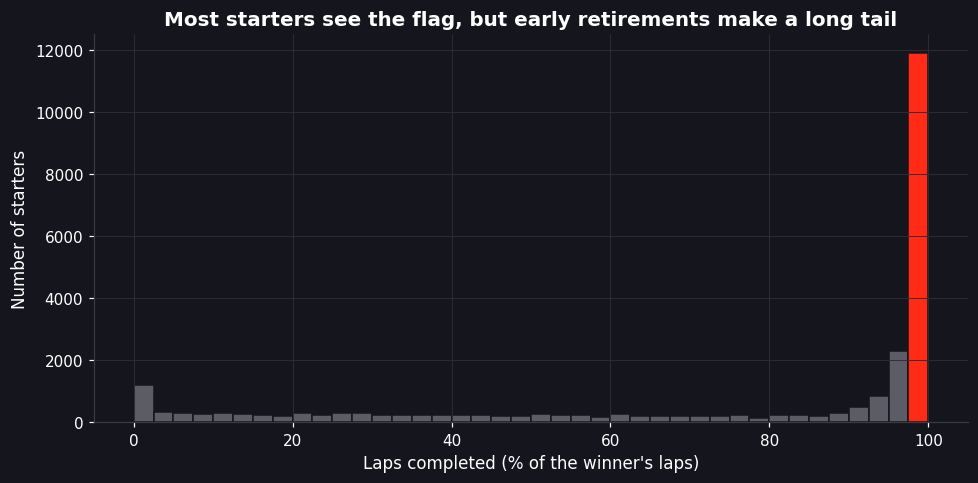

share of starters who completed at least 97.5% of the laps: 48%


In [25]:
# laps completed as a share of the race winner's laps, so short and long races compare
race_laps = df.groupby("raceId")["laps"].transform("max")
share = (df.loc[df["starter"], "laps"] / race_laps[df["starter"]] * 100).clip(0, 100)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(share, bins=40, color=GREY, edgecolor=BG)
# highlight the bar that holds the drivers who reached the flag
ax.hist(share[share >= 97.5], bins=[97.5, 100], color=RED, edgecolor=BG)
ax.set_title("Most starters see the flag, but early retirements make a long tail")
ax.set_xlabel("Laps completed (% of the winner's laps)")
ax.set_ylabel("Number of starters")
save(fig, "01_laps_completed_hist")
plt.show()
print(f"share of starters who completed at least 97.5% of the laps: {(share >= 97.5).mean():.0%}")

*Each bar is a group of starters by how much of the race they completed (1950–2024). The red bar
is drivers who finished on the lead lap or close to it. The flat tail on the left is retirements,
and many of them happen in the first laps.*

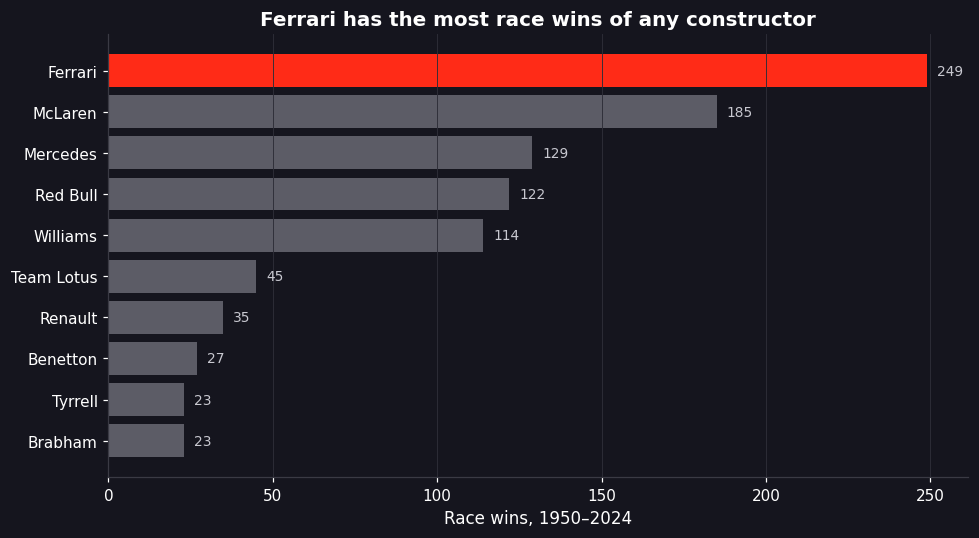

In [26]:
team_wins = wins["team"].value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
colors = [RED if t == team_wins.idxmax() else GREY for t in team_wins.index]
ax.barh(team_wins.index, team_wins.values, color=colors)
for i, v in enumerate(team_wins.values):
    ax.text(v + 3, i, str(v), va="center", color=LIGHT, fontsize=9)
ax.set_title(f"{team_wins.idxmax()} has the most race wins of any constructor")
ax.set_xlabel("Race wins, 1950–2024")
ax.grid(axis="y", visible=False)
save(fig, "02_top_constructors_wins")
plt.show()

*Top 10 constructors by race wins, 1950–2024. Ferrari leads, and McLaren and Mercedes follow.
Mercedes got most of its wins in only 11 seasons.*

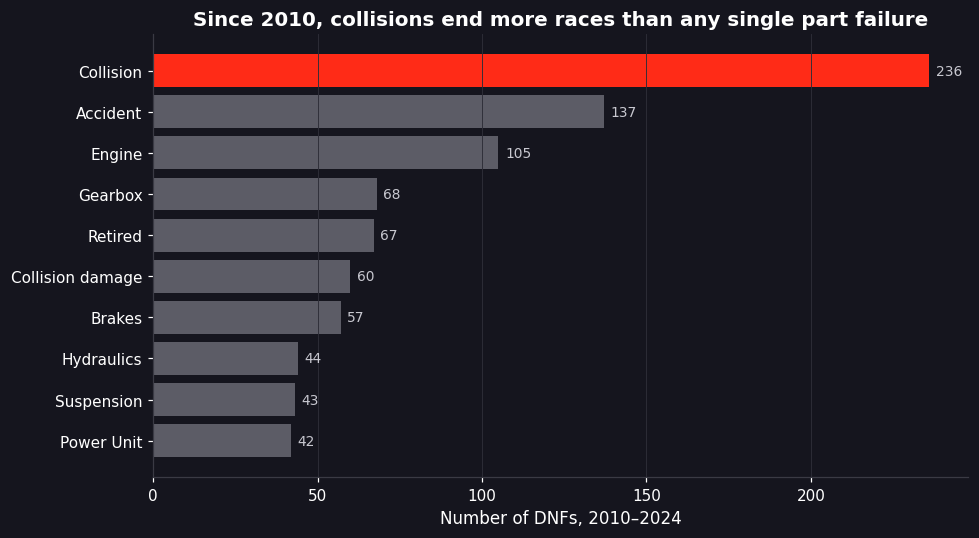

In [27]:
dnf_modern = modern[modern["dnf"]]
reasons = dnf_modern["status"].value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
colors = [RED if r == reasons.idxmax() else GREY for r in reasons.index]
ax.barh(reasons.index, reasons.values, color=colors)
for i, v in enumerate(reasons.values):
    ax.text(v + 2, i, str(v), va="center", color=LIGHT, fontsize=9)
ax.set_title("Since 2010, collisions end more races than any single part failure")
ax.set_xlabel("Number of DNFs, 2010–2024")
ax.grid(axis="y", visible=False)
save(fig, "03_dnf_reasons_modern")
plt.show()

*Top 10 DNF reasons, 2010–2024. "Collision" is the single biggest label. Mechanical problems are
split over many labels (engine, gearbox, brakes, hydraulics...), so together they are still the
largest group.*

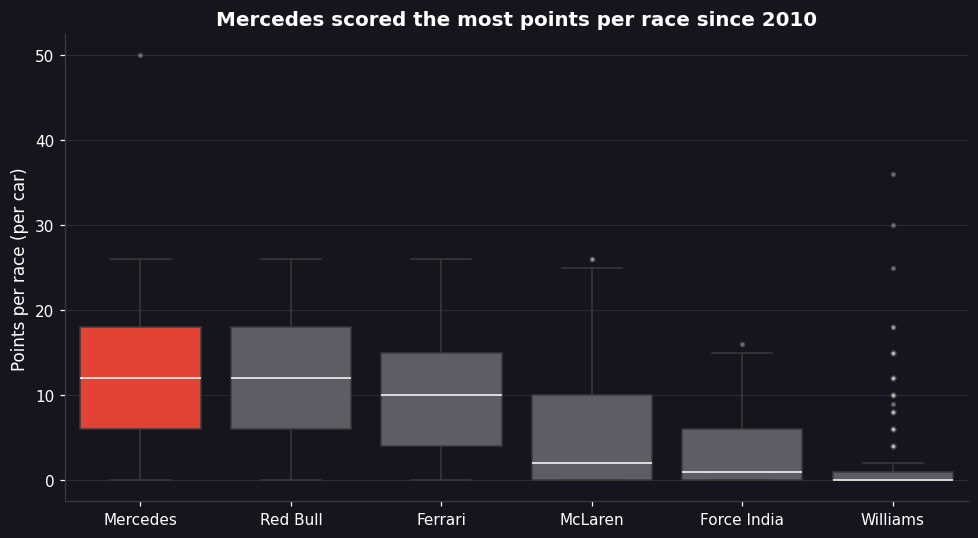

top teams by total points 2010–2024: ['Mercedes', 'Red Bull', 'Ferrari', 'McLaren', 'Force India', 'Williams']


In [28]:
top_teams = modern.groupby("team")["points"].sum().nlargest(6).index.tolist()
box_data = modern[modern["team"].isin(top_teams) & modern["starter"]]
order = box_data.groupby("team")["points"].mean().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=box_data, x="team", y="points", order=order, ax=ax,
            palette={t: RED if t == order[0] else GREY for t in order}, hue="team", legend=False,
            linewidth=1, flierprops={"markerfacecolor": LIGHT, "markersize": 3, "alpha": 0.5},
            medianprops={"color": "white"})
ax.set_title(f"{order[0]} scored the most points per race since 2010")
ax.set_xlabel("")
ax.set_ylabel("Points per race (per car)")
save(fig, "04_points_by_team_box")
plt.show()
print("top teams by total points 2010–2024:", top_teams)

*Points per car per race, 2010–2024, for the six teams with the most points. Mercedes and Red Bull
both have a median of 12 points. Force India and Williams mostly score 0 or 1. The dots at 50 and 36
are the 2014 Abu Dhabi race, which gave double points.*

### 5.2 Bivariate and multivariate

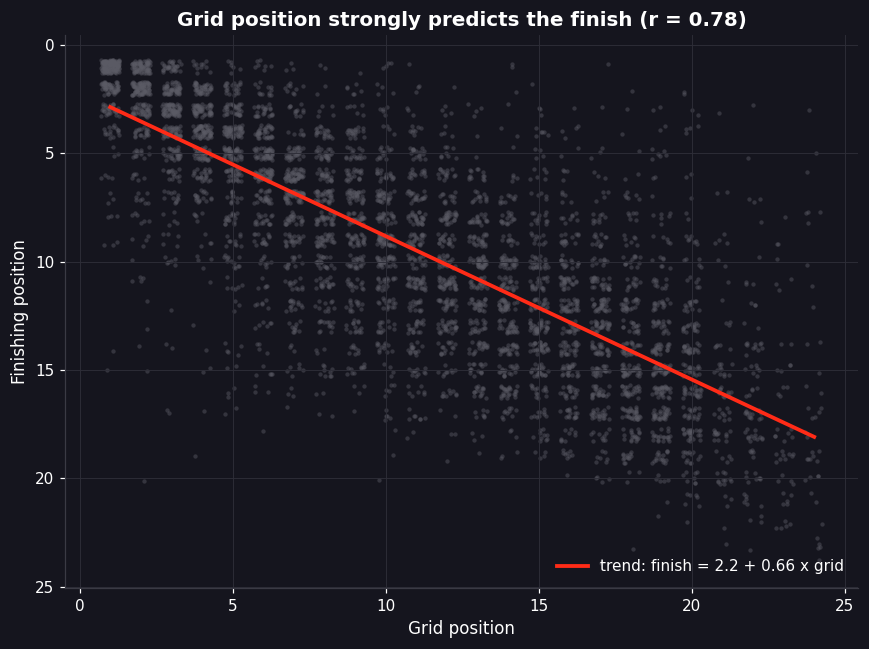

In [29]:
fin = modern[modern["finished"] & modern["grid_clean"].notna()]
r = fin["grid_clean"].corr(fin["positionOrder"])

rng = np.random.default_rng(42)
jx = fin["grid_clean"] + rng.uniform(-0.3, 0.3, len(fin))
jy = fin["positionOrder"] + rng.uniform(-0.3, 0.3, len(fin))
slope, intercept = np.polyfit(fin["grid_clean"], fin["positionOrder"], 1)
xs = np.array([1, fin["grid_clean"].max()])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(jx, jy, s=8, color=GREY, alpha=0.45, linewidths=0)
ax.plot(xs, intercept + slope * xs, color=RED, linewidth=2.5, label=f"trend: finish = {intercept:.1f} + {slope:.2f} x grid")
ax.set_title(f"Grid position strongly predicts the finish (r = {r:.2f})")
ax.set_xlabel("Grid position")
ax.set_ylabel("Finishing position")
ax.invert_yaxis()
ax.legend(loc="lower right", frameon=False)
save(fig, "05_grid_vs_finish_scatter")
plt.show()

*Classified finishers 2010–2024, with a little jitter so points do not sit on top of each other.
Pearson r is about 0.78. Drivers move a few places, but a car that starts at the back very rarely
finishes at the front.*

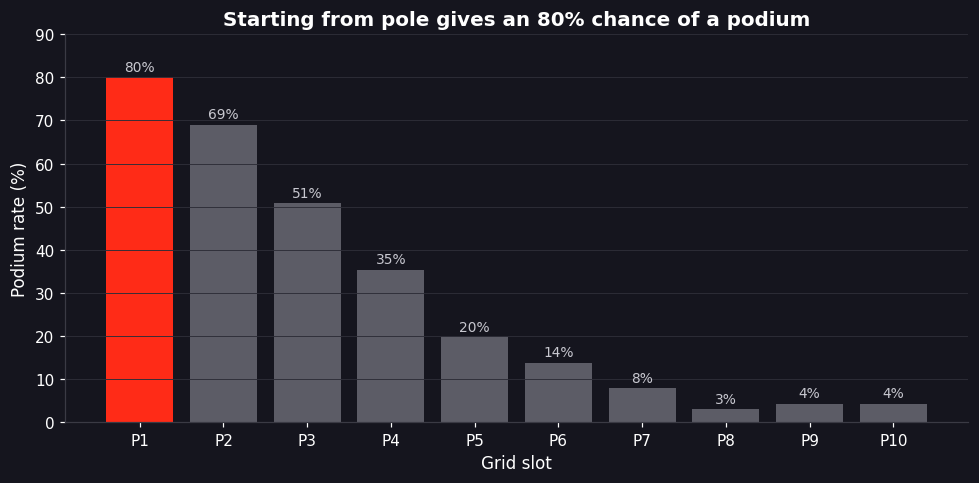

In [30]:
front10 = modern[modern["grid_clean"].between(1, 10)]
podium_rate = front10.groupby("grid_clean")["podium"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
labels = [f"P{int(g)}" for g in podium_rate.index]
ax.bar(labels, podium_rate.values, color=[RED] + [GREY] * 9)
for i, v in enumerate(podium_rate.values):
    ax.text(i, v + 1.5, f"{v:.0f}%", ha="center", color=LIGHT, fontsize=9)
ax.set_title("Starting from pole gives an 80% chance of a podium")
ax.set_xlabel("Grid slot")
ax.set_ylabel("Podium rate (%)")
ax.set_ylim(0, 90)
ax.grid(axis="x", visible=False)
save(fig, "06_podium_rate_by_grid")
plt.show()

*Share of starts from each grid slot that ended on the podium, 2010–2024. The chance drops fast:
from P5 it is 1 in 5, and from P8 to P10 it is almost zero.*

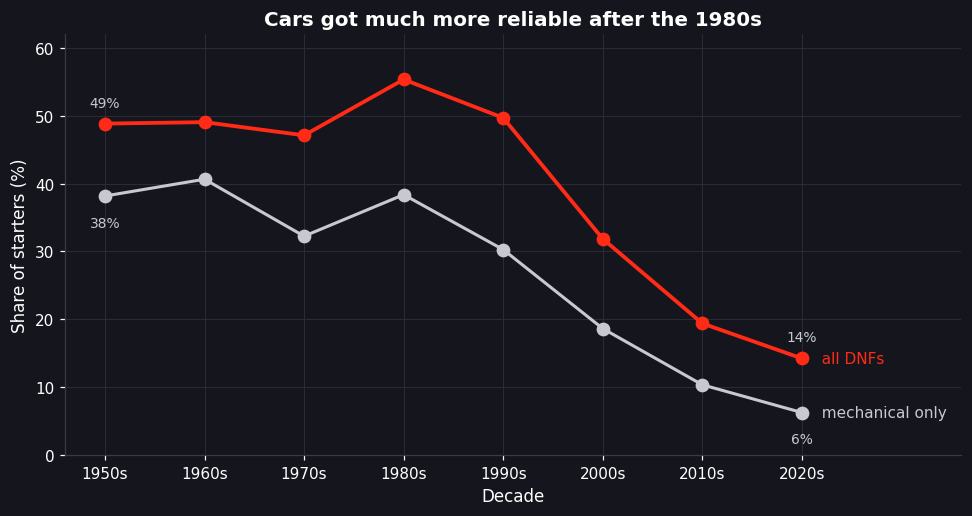

,DNF rate %,mechanical DNF %
decade,,
1950,49.0,38.0
1960,49.0,41.0
1970,47.0,32.0
1980,55.0,38.0
1990,50.0,30.0
2000,32.0,19.0
2010,19.0,10.0
2020,14.0,6.0


In [31]:
dnf_rate = starters.groupby("decade")["dnf"].mean() * 100
mech_rate = starters.assign(mech=starters["dnf_type"].eq("Mechanical")).groupby("decade")["mech"].mean() * 100
x = [f"{d}s" for d in dnf_rate.index]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(x, dnf_rate.values, color=RED, linewidth=2.5, marker="o", markersize=8)
ax.plot(x, mech_rate.values, color=LIGHT, linewidth=2, marker="o", markersize=8)
ax.text(len(x) - 1 + 0.1, dnf_rate.values[-1], "  all DNFs", color=RED, va="center")
ax.text(len(x) - 1 + 0.1, mech_rate.values[-1], "  mechanical only", color=LIGHT, va="center")
for i, (a, b) in enumerate(zip(dnf_rate.values, mech_rate.values)):
    if i in (0, len(x) - 1):
        ax.text(i, a + 2.5, f"{a:.0f}%", ha="center", color=LIGHT, fontsize=9)
        ax.text(i, b - 4.5, f"{b:.0f}%", ha="center", color=LIGHT, fontsize=9)
ax.set_xlim(-0.4, len(x) + 0.6)
ax.set_ylim(0, 62)
ax.set_title("Cars got much more reliable after the 1980s")
ax.set_xlabel("Decade")
ax.set_ylabel("Share of starters (%)")
save(fig, "07_dnf_rate_by_decade")
plt.show()
pd.DataFrame({"DNF rate %": dnf_rate.round(0), "mechanical DNF %": mech_rate.round(0)})

*DNF rate among starters per decade (red), and the part caused by mechanical failure (grey).
Around half of all starters retired until the 1980s. In the 2020s it is about 1 in 7, and
mechanical failures went from about 1 in 3 starters to about 1 in 16.*

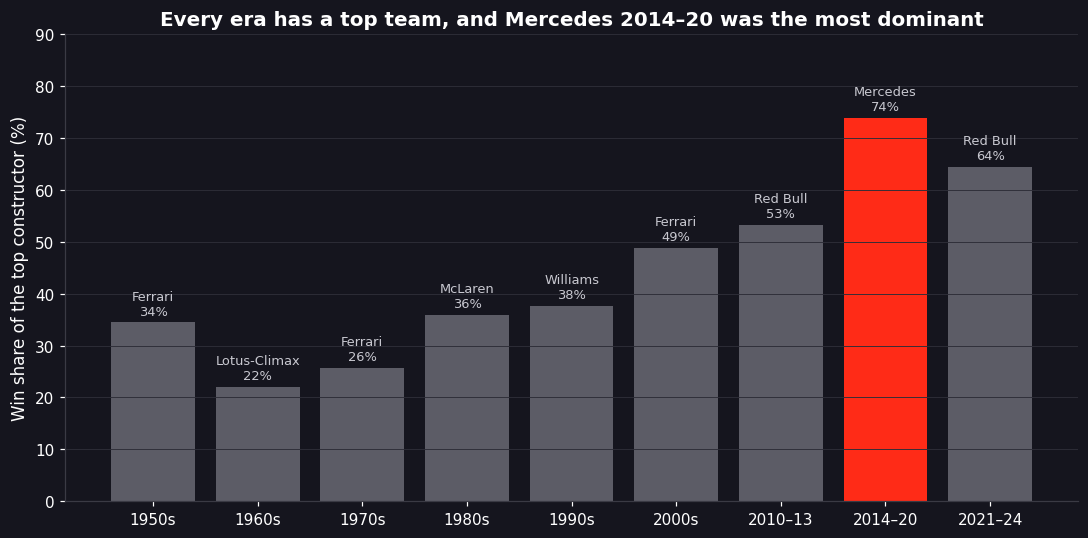

,era,team,wins,total,share
0,1950s,Ferrari,30,87,34.482759
1,1960s,Lotus-Climax,22,100,22.000000
2,1970s,Ferrari,37,144,25.694444
3,1980s,McLaren,56,156,35.897436
4,1990s,Williams,61,162,37.654321
5,2000s,Ferrari,85,174,48.850575
6,2010–13,Red Bull,41,77,53.246753
7,2014–20,Mercedes,102,138,73.913043
8,2021–24,Red Bull,58,90,64.444444


In [32]:
eras = [("1950s", 1950, 1959), ("1960s", 1960, 1969), ("1970s", 1970, 1979), ("1980s", 1980, 1989),
        ("1990s", 1990, 1999), ("2000s", 2000, 2009), ("2010–13", 2010, 2013),
        ("2014–20", 2014, 2020), ("2021–24", 2021, 2024)]

rows = []
for label, start, end in eras:
    w = wins[wins["year"].between(start, end)]["team"].value_counts()
    rows.append({"era": label, "team": w.index[0], "wins": w.iloc[0], "total": w.sum(),
                 "share": w.iloc[0] / w.sum() * 100})
era_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 5))
colors = [RED if s == era_df["share"].max() else GREY for s in era_df["share"]]
ax.bar(era_df["era"], era_df["share"], color=colors)
for i, row in era_df.iterrows():
    ax.text(i, row["share"] + 1.5, f"{row['team']}\n{row['share']:.0f}%", ha="center", color=LIGHT, fontsize=8.5)
ax.set_title("Every era has a top team, and Mercedes 2014–20 was the most dominant")
ax.set_ylabel("Win share of the top constructor (%)")
ax.set_ylim(0, 90)
ax.grid(axis="x", visible=False)
save(fig, "08_top_constructor_by_era")
plt.show()
era_df

*Win share of the most successful constructor in each era. In the 1960s and 1970s wins were spread
out. Since 2000 the top team usually wins half the races or more.*

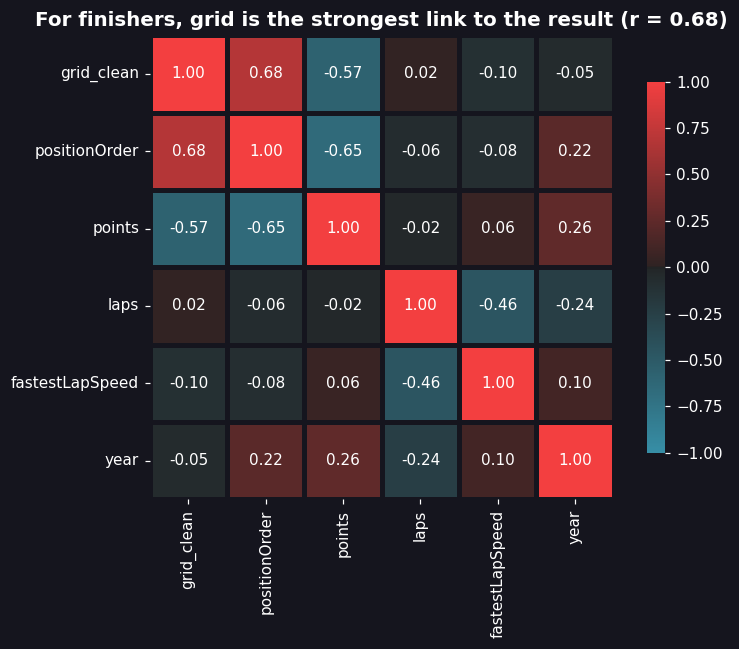

In [33]:
corr_cols = ["grid_clean", "positionOrder", "points", "laps", "fastestLapSpeed", "year"]
corr = df[df["finished"]][corr_cols].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
cmap = sns.diverging_palette(220, 12, s=85, l=55, center="dark", as_cmap=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap=cmap, vmin=-1, vmax=1, center=0, square=True,
            linewidths=2, linecolor=BG, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title(f"For finishers, grid is the strongest link to the result (r = {corr.loc['grid_clean', 'positionOrder']:.2f})")
ax.grid(False)
save(fig, "09_correlation_heatmap")
plt.show()

*Pearson correlation, classified finishers 1950–2024 (pairwise complete rows). Grid vs finishing
position is 0.68. Points and position are tied by the scoring rules, so the -0.65 is expected.
Year has almost no link with the result. Fastest lap speed only exists from 2004 and mostly tracks
the circuit (slow tracks like Monaco have more laps).*

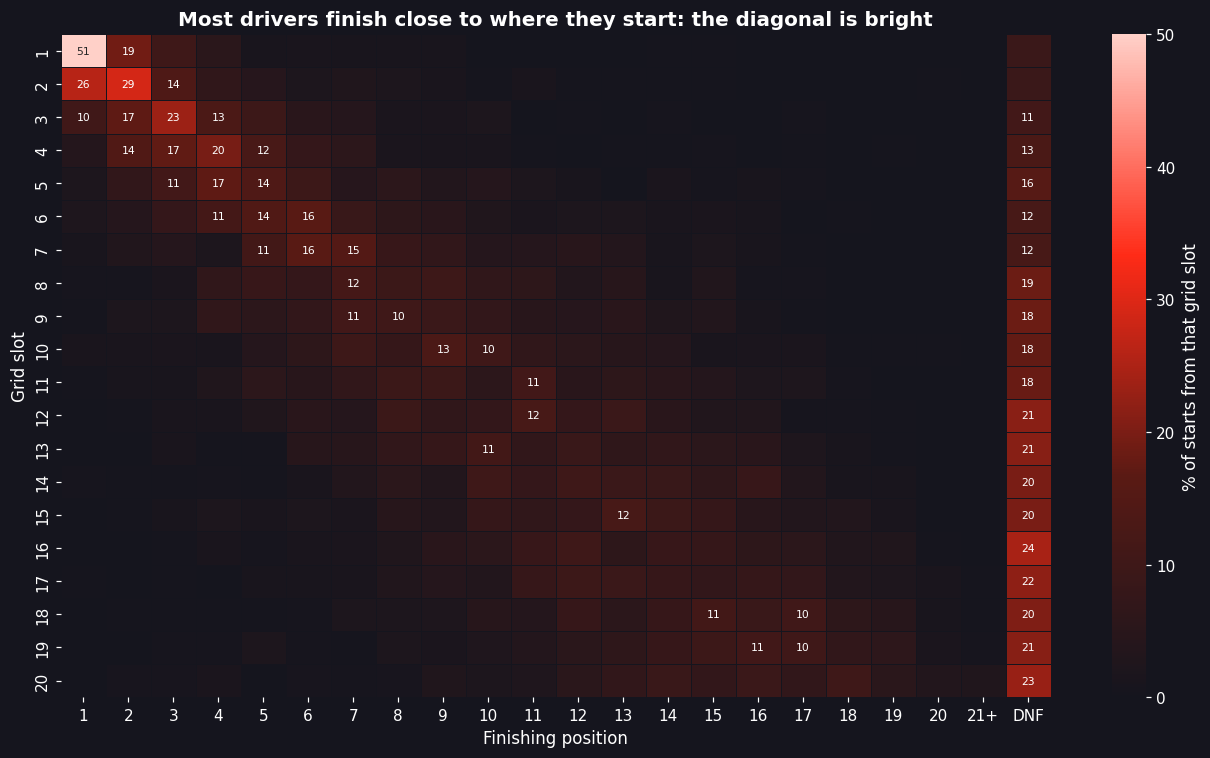

In [34]:
grid20 = modern[modern["grid_clean"].between(1, 20) & modern["starter"]].copy()
grid20["result"] = np.where(grid20["finished"], grid20["positionOrder"].clip(upper=21).astype(int), 99)
table = pd.crosstab(grid20["grid_clean"].astype(int), grid20["result"], normalize="index") * 100
table.columns = [str(c) if c <= 20 else ("21+" if c == 21 else "DNF") for c in table.columns]

fig, ax = plt.subplots(figsize=(12, 7))
cmap = sns.blend_palette([BG, "#5A1A14", RED, "#FFD0C8"], as_cmap=True)
sns.heatmap(table, cmap=cmap, vmin=0, vmax=50, linewidths=0.5, linecolor=BG,
            annot=table.round(0).astype(int).where(table >= 10).fillna(0).astype(int).replace(0, ""),
            fmt="", annot_kws={"fontsize": 7}, cbar_kws={"label": "% of starts from that grid slot"}, ax=ax)
ax.set_title("Most drivers finish close to where they start: the diagonal is bright")
ax.set_xlabel("Finishing position")
ax.set_ylabel("Grid slot")
ax.grid(False)
save(fig, "10_grid_finish_heatmap")
plt.show()

*Each row is one grid slot, 2010–2024, and shows where those starts ended (row adds up to 100%).
Numbers are shown for cells of 10% or more. Pole ends in a win about half the time. The DNF column
grows from about 9% on the front row to about 20% at the back, so cars at the back retire about twice as often.*

### 5.3 Headline numbers

These are the numbers used in my presentation, recomputed here from the clean data.

In [35]:
mw = modern[modern["win"]]
n_races = modern["raceId"].nunique()
within3 = ((fin["grid_clean"] - fin["positionOrder"]).abs() <= 3).mean()

pod = podium_rate.round(0).astype(int).tolist()
dnf_dec = dnf_rate.round(0).astype(int).tolist()
causes = modern.loc[modern["dnf"], "dnf_type"].value_counts(normalize=True) * 100
merc = wins[wins["year"].between(2014, 2020)]["team"].value_counts()
rb23 = wins[wins["year"] == 2023]["team"].value_counts()
drivers_top = wins["driver"].value_counts().head(3)

headline = pd.DataFrame([
    ("Rows / races / drivers / constructors / seasons",
     f"{len(df):,} / {df['raceId'].nunique():,} / {df['driverId'].nunique()} / {df['constructorId'].nunique()} / {df['year'].nunique()}"),
    ("Pole sitter wins, 2010–2024", f"{(mw['grid_clean'] == 1).mean():.0%}"),
    ("Front-row (grid <= 2) wins, 2010–2024", f"{(mw['grid_clean'] <= 2).mean():.0%}"),
    ("Races won from outside the top 10, 2010–2024", f"{(mw['grid_clean'] > 10).sum()} of {n_races}"),
    ("Grid vs finish correlation, classified finishers", f"{r:.2f}"),
    ("Podium rate by grid P1 to P10 (%)", ", ".join(map(str, pod))),
    ("Finishers within 3 places of their grid slot", f"{within3:.0%}"),
    ("DNF rate among starters by decade (%)", ", ".join(map(str, dnf_dec))),
    ("Mechanical DNF share of starters, 1950s to 2020s", f"{mech_rate.iloc[0]:.0f}% to {mech_rate.iloc[-1]:.0f}%"),
    ("Retirement causes, 2010–2024",
     f"{causes['Mechanical']:.0f}% mechanical, {causes['Crash/collision']:.0f}% crash/collision, {causes['Other']:.0f}% other"),
    ("Mercedes, 2014–2020", f"{merc['Mercedes']} of {merc.sum()} wins ({merc['Mercedes'] / merc.sum():.0%})"),
    ("Red Bull, 2023", f"{rb23['Red Bull']} of {rb23.sum()} wins"),
    ("Top era winners", ", ".join(f"{e} {t} {s:.0f}%" for e, t, s in zip(era_df['era'], era_df['team'], era_df['share']))),
    ("Most wins, 1950–2024", ", ".join(f"{d.split()[-1]} {n}" for d, n in drivers_top.items())),
], columns=["stat", "value"])

with pd.option_context("display.max_colwidth", None):
    display(headline)

,stat,value
0,Rows / races / drivers / constructors / seasons,"26,759 / 1,125 / 861 / 211 / 75"
1,"Pole sitter wins, 2010–2024",51%
2,"Front-row (grid <= 2) wins, 2010–2024",77%
3,"Races won from outside the top 10, 2010–2024",4 of 305
4,"Grid vs finish correlation, classified finishers",0.78
5,Podium rate by grid P1 to P10 (%),"80, 69, 51, 35, 20, 14, 8, 3, 4, 4"
6,Finishers within 3 places of their grid slot,67%
7,DNF rate among starters by decade (%),"49, 49, 47, 55, 50, 32, 19, 14"
8,"Mechanical DNF share of starters, 1950s to 2020s",38% to 6%
9,"Retirement causes, 2010–2024","51% mechanical, 41% crash/collision, 8% other"


In [36]:
# the rare wins from outside the top 10
mw[mw["grid_clean"] > 10][["year", "race_name", "driver", "team", "grid"]]

,year,race_name,driver,team,grid
21403,2012,European Grand Prix,Fernando Alonso,Ferrari,11
23980,2018,German Grand Prix,Lewis Hamilton,Mercedes,14
25660,2022,Belgian Grand Prix,Max Verstappen,Red Bull,14
26679,2024,São Paulo Grand Prix,Max Verstappen,Red Bull,17


Two of these differ from the first version of my presentation:

- **Finishers within 3 places of their grid slot: 67%** (the slides say 69%). Here I count classified
  finishers with a real grid slot and compare grid with `positionOrder`.
- **Mechanical DNF share of starters in the 1950s: 38%** (the slides say 31%). My mechanical group
  is everything that is not a crash or "other", so it includes old labels like Magneto, Axle and
  Ignition. A shorter list of mechanical labels gives a lower 1950s number. The 2020s value (6%)
  is the same either way.

Everything else matches.

## Step 6: Insights summary

**Patterns**
- Qualifying matters a lot. Since 2010 the pole sitter won 51% of races, the front row won 77%,
  and only 4 of 305 races were won from outside the top 10.
- Each era has one team on top: Ferrari in the 2000s, Red Bull in 2010–13, Mercedes in 2014–20,
  Red Bull again in 2021–24.
- Reliability got much better. About half of all starters retired until the 1980s. In the 2020s it is 14%.

**Relationships**
- Grid vs finish: r = 0.78 for classified finishers. Two in three finishers end within 3 places of their start.
- Podium chance falls fast with grid slot: 80% from P1, 20% from P5, about 4% from P8 to P10.
- Since 2010, retirements are 51% mechanical and 41% crashes or collisions.

**Outliers**
- Red Bull won 21 of 22 races in 2023.
- Mercedes won 102 of 138 races (74%) from 2014 to 2020, the highest share of any era.
- Only four races since 2010 were won from outside the top 10 (see the table in 5.3).

**Takeaway:** the race is not fully decided on Saturday, but most of it is. Grid position and the car
explain most of the result. Sunday mostly shuffles drivers by a few places.

## Step 7: Optional model: predicting a podium

A simple logistic regression that predicts `podium` from grid slot, team and year, trained on
2010–2024 starters with a real grid slot. Teams outside the top 6 by points are grouped as "Other".

In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

data = modern[modern["starter"] & modern["grid_clean"].notna()].copy()
data["team_group"] = data["team"].where(data["team"].isin(top_teams), "Other")

X = data[["grid_clean", "team_group", "year"]]
y = data["podium"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

prep = ColumnTransformer([
    ("num", StandardScaler(), ["grid_clean", "year"]),
    ("team", OneHotEncoder(handle_unknown="ignore"), ["team_group"]),
])
models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))]),
}

scores = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    scores.append({"model": name,
                   "precision": precision_score(y_test, pred, zero_division=0),
                   "recall": recall_score(y_test, pred),
                   "F1": f1_score(y_test, pred),
                   "ROC-AUC": roc_auc_score(y_test, proba)})

print(f"train {len(X_train)}, test {len(X_test)}, podium rate {y.mean():.1%}")
pd.DataFrame(scores).set_index("model").round(3)

train 4753, test 1585, podium rate 14.4%


,precision,recall,F1,ROC-AUC
model,,,,
Dummy (most frequent),0.000,0.000,0.000,0.500
Logistic regression,0.667,0.568,0.613,0.914


In [38]:
# what the model says for a few example starts
examples = pd.DataFrame({"grid_clean": [1, 1, 5, 10], "team_group": ["Red Bull", "Other", "Ferrari", "Mercedes"],
                         "year": [2023, 2023, 2023, 2023]})
examples["podium chance"] = models["Logistic regression"].predict_proba(examples)[:, 1].round(2)
examples

,grid_clean,team_group,year,podium chance
0,1,Red Bull,2023,0.76
1,1,Other,2023,0.39
2,5,Ferrari,2023,0.33
3,10,Mercedes,2023,0.08


The dummy model always says "no podium", so it is right most of the time but finds no podiums at all.
The logistic regression ranks starts well (ROC-AUC about 0.91). It finds a bit more than half of
the podiums, and about two in three of its podium calls are right. Grid slot does most of the work and team adds the rest. The Streamlit app uses this
same model for its "predict podium chance" widget.

## Step 8: Final summary

**Main insights**
1. Grid position is the strongest single factor in the result: pole wins about half the races since 2010,
   and 77% of winners started on the front row.
2. One constructor dominates almost every era, and the dominance is stronger in the modern era.
3. Cars are far more reliable. The DNF rate fell from about 50% to 14%, mostly because mechanical
   failures dropped from about 38% of starters to 6%.

**What I learned**
- How to join several tables by ID and check that a merge did not lose or duplicate rows.
- That missing values are not always NaN. Here they were the text `\N`, and `isnull()` missed them.
- How to turn messy labels (130+ status values) into a few useful groups.
- That a good baseline is needed to judge a model. Accuracy alone looks good even for a model that does nothing.

**Limitations**
- The points system changed many times, so I compare positions and wins instead of points across eras.
- Status labels are not consistent across decades, so the mechanical vs crash split is approximate.
- These tables have no weather, tyre or strategy data.
- Grids before the 1980s had different sizes, so grid slots are not fully comparable across eras.

**Future work**
- Add the `pit_stops` and `lap_times` tables to see where places are gained or lost.
- Compare street circuits with permanent tracks.
- Improve the podium model with qualifying gaps, driver form and circuit type.